# The most important continuous distributions

Now that we have discussed the Gaussian distribution at length, we want an overview of some of the most important continuous distributions, much as we did for the discrete ones in the chapter [The most important discrete distributions](important-discrete-distributions.ipynb). For this we use the Python module `scipy.stats`.


## SciPy Statistics

In [1]:
import numpy as np
np.random.seed(12321)

import scipy.stats as st

# Create a random variable with an N(3,2^2) distribution:
X = st.norm(loc=3, scale=2)
# draw samples:
Xsamples = X.rvs(size=4)
print("some examples:",Xsamples)

some examples: [4.02801895 1.9033209  6.49477125 1.83362523]


In [2]:
# Check the distribution:
Xsamples = X.rvs(size=1000)
print("mean:", np.mean(Xsamples), "expected", X.mean()) # 3
print("std:", np.std(Xsamples), "expected", X.std()) # 2
print("3rd moment:", X.moment(3))
print("4th moment:", X.moment(4))
print("entropy:", X.entropy())

mean: 3.0004822746684243 expected 3.0
std: 1.9994507762900595 expected 2.0
3rd moment: 62.99999999999999
4th moment: 344.99999999999994
entropy: 2.112085713764618


In [3]:
# Fit the data:
mu, sigma = st.norm.fit(Xsamples)
print(mu, sigma)

3.0004822746684243 1.9994507762900595


There are further useful methods, such as `st.norm.sf`, the 'survival function', defined as 1-cdf, or `st.norm.logpdf` for when you want to work directly with the logarithm of the density function (both are potentially faster than computing it by hand).

## Matplotlib

For each distribution we will look at plots of the density function (pdf) and the cumulative distribution function (cdf). For this we use the Python module `matplotlib.pyplot`, which emulates the behaviour of MATLAB. We will come back to Matplotlib in more detail.

As a first example we simulate the continuous distribution on $[5,8)$ from the chapter [Continuous distributions](continuous-distributions.md): first one of the numbers $5, 6, 7$ is chosen with weights $\frac{4}{7}, \frac{2}{7}, \frac{1}{7}$, then a uniformly distributed number from $[0,1)$ is added. That chapter also works out the expected value $6 + \frac{1}{14}$, which we can compare with the mean of the sample.

In [4]:
from matplotlib import pyplot as plt

sample[:10] = [5.96301841 5.60942173 5.72908826 5.80068973 5.59819708 5.35377228
 6.093922   6.36189002 5.42430139 5.87334923]


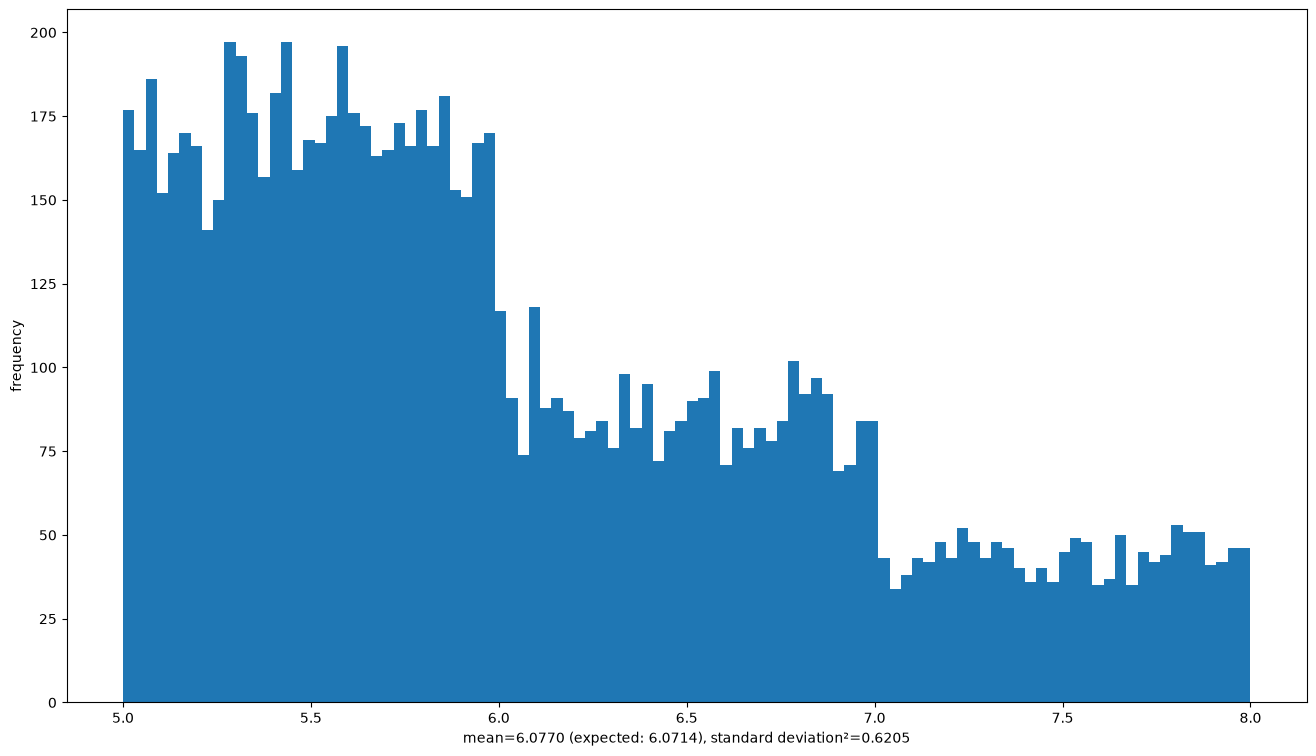

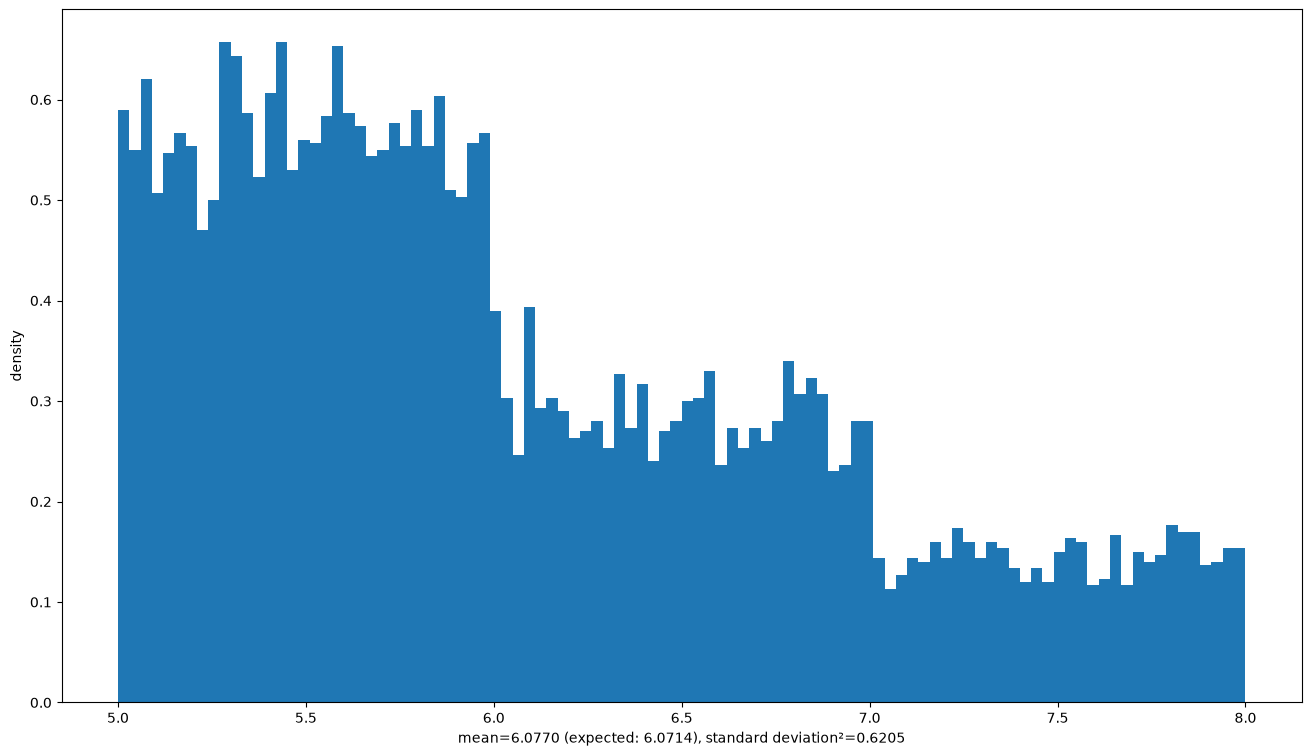

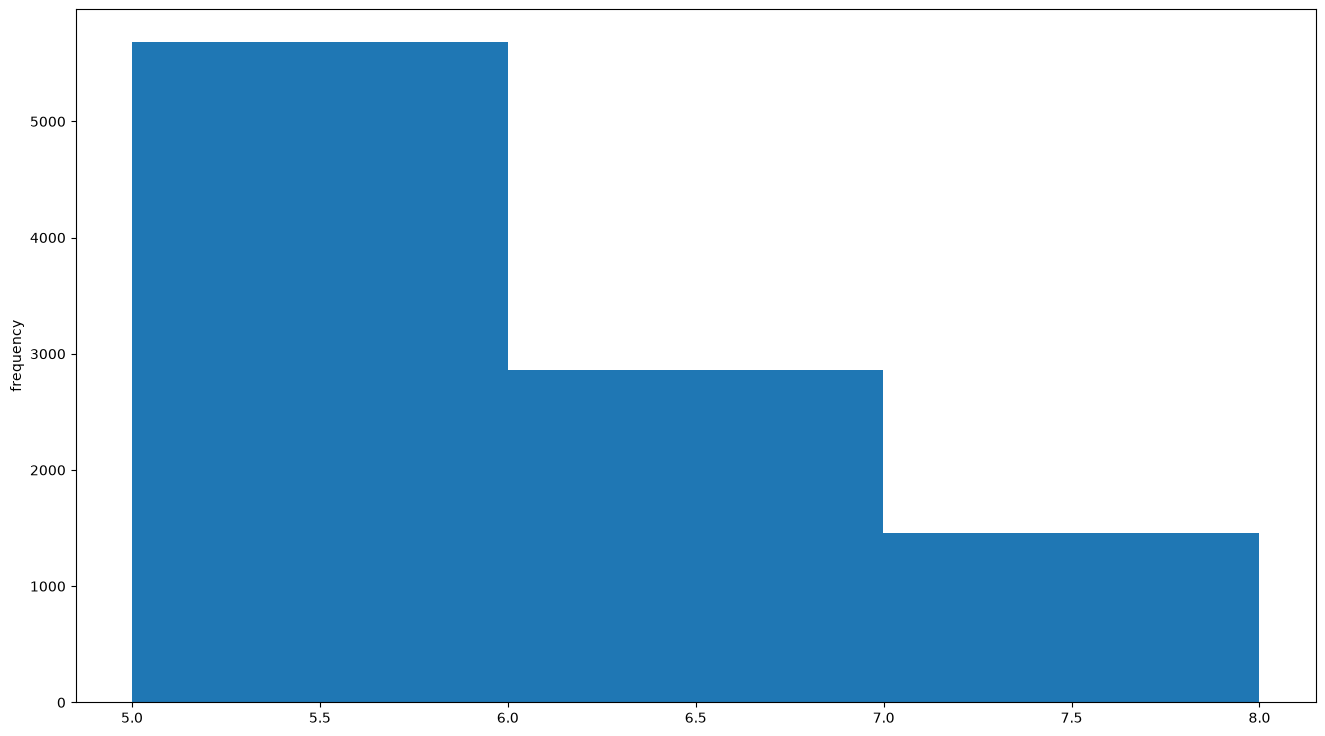

In [5]:
# Adjust the size of the plot output:
plt.rcParams["figure.figsize"] = (16,9)

# Sample from the distribution on [5,8) from the chapter Continuous distributions:
sample = np.random.choice(3, 10000, p=[4/7,2/7,1/7]) + 5 + np.random.random(10000)
print("sample[:10] =", sample[:10])
# Plot the histogram:
plt.hist(sample, bins=100)
plt.ylabel("frequency")
plt.xlabel(f"mean={np.mean(sample):.4f} (expected: {6+1/14:.4f}), standard deviation²={np.std(sample)**2:.4f}")
plt.show()

plt.hist(sample, bins=100, density=True)
plt.ylabel("density")
plt.xlabel(f"mean={np.mean(sample):.4f} (expected: {6+1/14:.4f}), standard deviation²={np.std(sample)**2:.4f}")
plt.show()

# Histogram with few bins:
plt.hist(sample, bins=3)
plt.ylabel("frequency")
plt.show()

To plot a function we define it as a Python function and evaluate it at enough points; the plot is then interpolated between them:

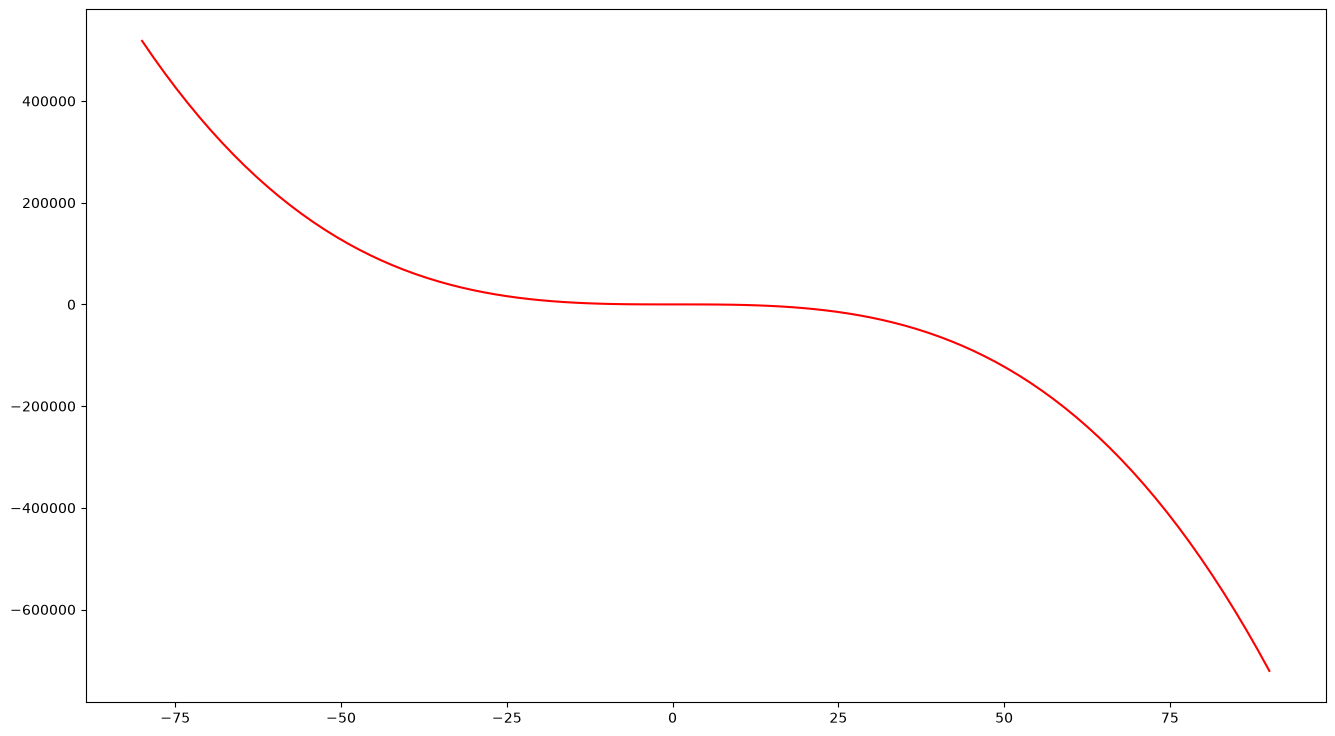

In [6]:
# Plot the function x |-> 3+2x+x²-x³ on the interval [-80,90]:
def f(x):
    return 3 + 2*x + x**2 - x**3

x = np.linspace(-80, 90, 100)
plt.plot(x, f(x), color='red')
plt.show()

With that, we turn to the most important continuous distributions:

## Normal distribution

* Parameters $\mu,\sigma$, notation $\mathcal{N}(\mu,\sigma^2)$
* Density $\phi(x) = \frac{1}{\sigma\sqrt{2\pi}} e^{-\frac{(x-\mu)^2}{2\sigma^2}}$
* Expected value $\mu$
* Variance $\sigma^2$
* All odd central moments are $0$ (the density is symmetric, so an odd moment $\neq 0$ is a sign of asymmetry)
* Maximum entropy for a fixed expected value, a fixed variance and support all of $\mathbb{R}$
* Central limit theorem: for iid $X_i$ with expected value $\mu$ and variance $\sigma^2$, the standardised sum $Z_N = \frac{1}{\sigma\sqrt{N}} \sum_{i=1}^N (X_i - \mu)$ is approximately $\mathcal{N}(0,1)$-distributed for large $N$, equivalently $\frac{1}{N}\sum_{i=1}^N X_i \approx \mathcal{N}\!\left(\mu, \frac{\sigma^2}{N}\right)$ (chapter [The normal distribution](normal-distribution.ipynb))
* Example applications:
  * Measurement errors in physical systems
  * Manufacturing precision
  * Biological quantities (body height etc.)

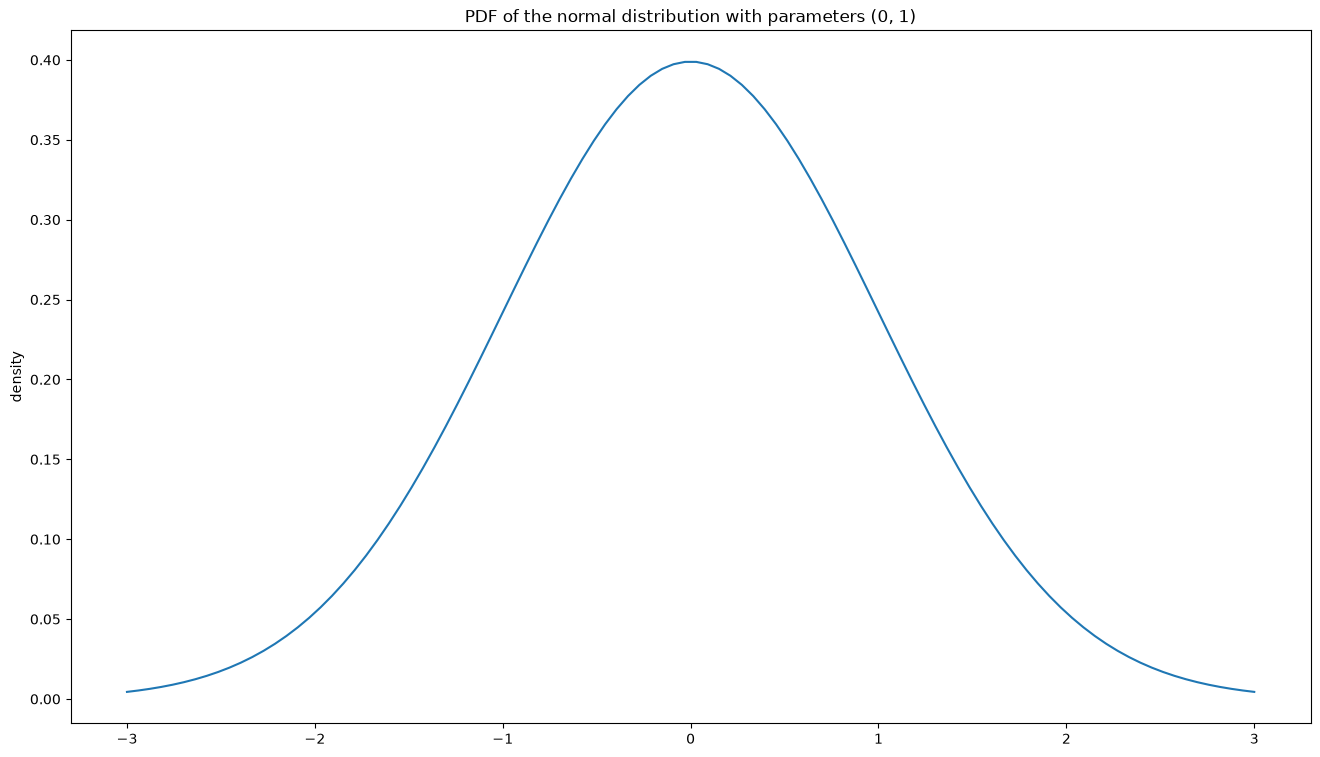

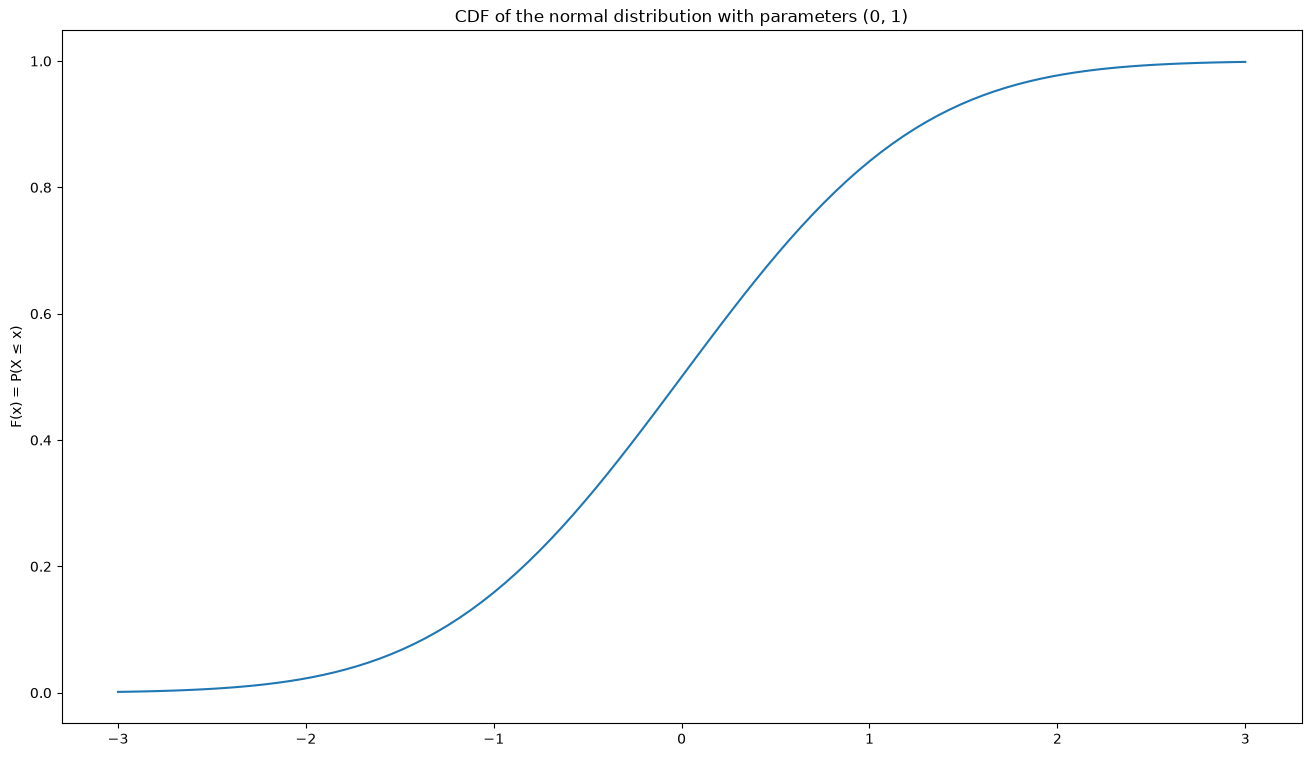

In [7]:
# For the plots:
def plotX(x, X, name, params):
    # First the density function:
    plt.plot(x, X.pdf(x))
    plt.ylabel('density')
    plt.title(f"PDF of the {name} with parameters {params}")
    plt.show()
    # Then the cumulative distribution function:
    plt.plot(x, X.cdf(x))
    plt.ylabel('F(x) = P(X ≤ x)')
    plt.title(f"CDF of the {name} with parameters {params}")
    plt.show()

x = np.linspace(-3,3,100)
mu, sigma = 0, 1
X = st.norm(loc=mu, scale=sigma)
name = "normal distribution"
plotX(x, X, name, (mu, sigma))

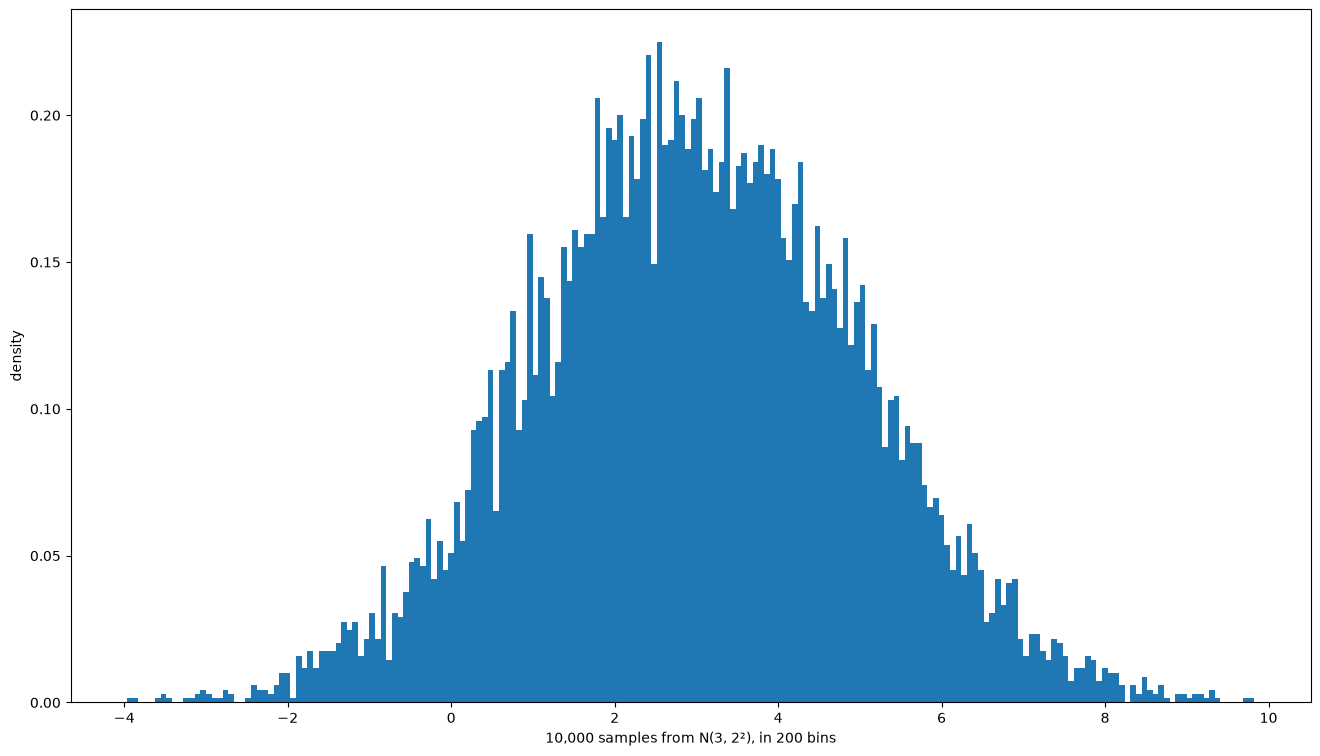

In [8]:
X = st.norm(loc=3, scale=2)
Xsamples = X.rvs(size=10000)
plt.hist(Xsamples, bins=200, density=True)
plt.xlabel("10,000 samples from N(3, 2²), in 200 bins")
plt.ylabel("density")
plt.show()

## Contaminated normal distribution

The contaminated normal distribution is a simple case of a *mixture model*, more precisely a *Gaussian mixture*.

* Parameters $\varepsilon,\mu_1,\sigma_1,\mu_2,\sigma_2$, notation $\varepsilon\mathcal{N}(\mu_1,\sigma_1^2) + (1-\varepsilon)\mathcal{N}(\mu_2,\sigma_2^2)$
* Density $\phi(x) = \frac{\varepsilon}{\sigma_1\sqrt{2\pi}} e^{-\frac{(x-\mu_1)^2}{2\sigma_1^2}} + \frac{1 - \varepsilon}{\sigma_2\sqrt{2\pi}} e^{-\frac{(x-\mu_2)^2}{2\sigma_2^2}}$
* Expected value $\varepsilon\mu_1 + (1-\varepsilon)\mu_2$
* Variance $\varepsilon\sigma_1^2 + (1 - \varepsilon)\sigma_2^2 + \varepsilon(1 - \varepsilon)(\mu_1-\mu_2)^2$
* Example applications: a two-stage process in which the outcome of a Bernoulli experiment decides which normal distribution is sampled from. One concrete experimental setup would be measuring the height of the participants in a computer science lecture. Gender is (approximately!) Bernoulli distributed (presumably not uniformly), and within each gender group height is then normally distributed (but with different means). The example also shows that every act of modelling has the potential to render invisible a part of reality that you may not want invisible at all. Fortunately, mixture models can also be set up with more than one parameter $\varepsilon$.

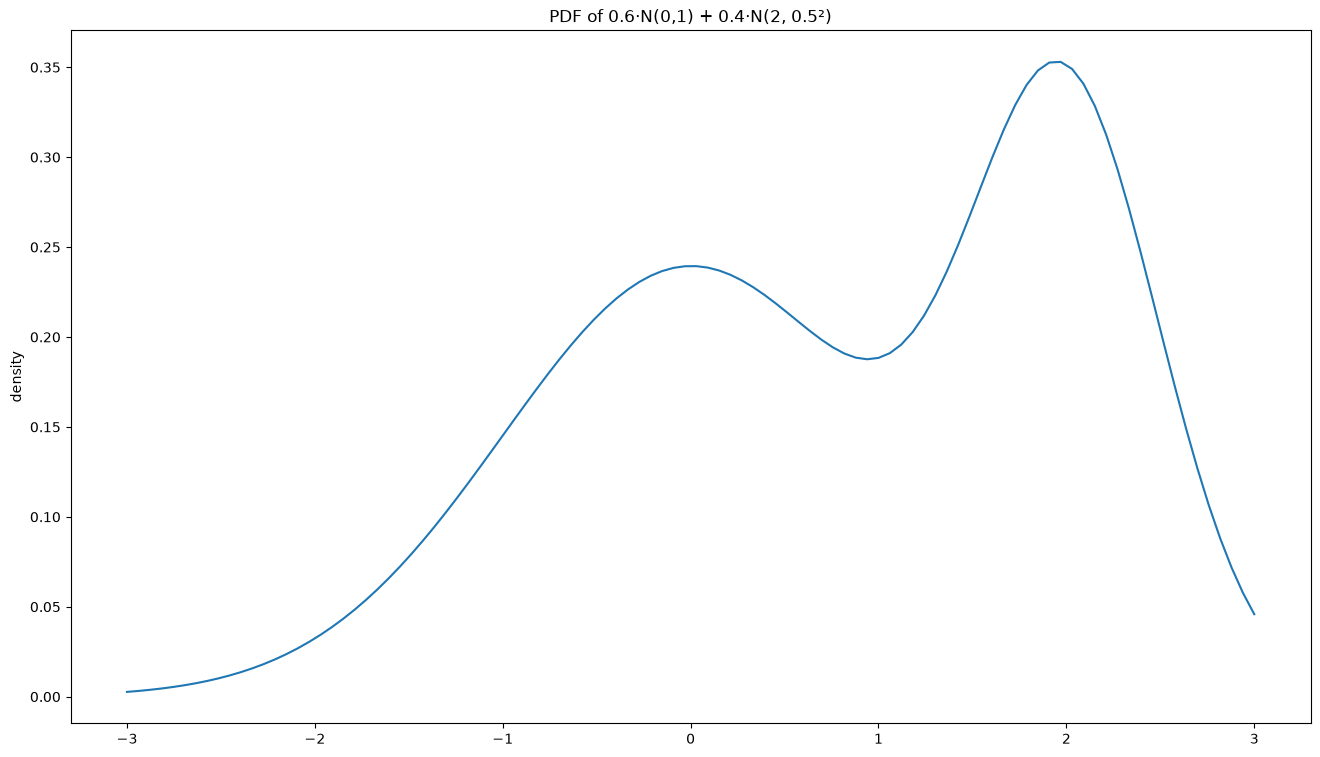

In [9]:
name = "0.6·N(0,1) + 0.4·N(2, 0.5²)"
def f(x, epsilon=0.6, mu1=0, sigma1=1, mu2=2, sigma2=0.5):
    norm1 = st.norm(loc=mu1, scale=sigma1)
    norm2 = st.norm(loc=mu2, scale=sigma2)
    return epsilon*norm1.pdf(x) + (1-epsilon)*norm2.pdf(x)

x = np.linspace(-3,3,100)
plt.plot(x, f(x))
plt.ylabel('density')
plt.title(f"PDF of {name}")
plt.show()

## Dirac distribution

* Parameter $\xi$, notation $\delta(\xi)$
* No density, but $P(X = \xi) = 1$
* Expected value $\xi$
* Variance $0$
* Entropy $0$ (read as a discrete distribution; it has no differential entropy)
* Example applications:
  * Writing down 'density functions' in the continuous sense for discrete distributions
  * Photographs of the night sky (taken with Hubble, say) – every star is a smeared-out heap of pixels (normally distributed), but the 'actual' distribution of the stars behind it is a sum of Dirac measures, since every star sits at exactly one point (the star's true extent is irrelevant at that distance). Some super-resolution techniques work with this model.

Strictly speaking the Dirac distribution cannot be plotted (there is no density, after all). Some people draw an arrow of length $1$ at $\xi$ by way of illustration.
The cumulative distribution function is a Heaviside step function:

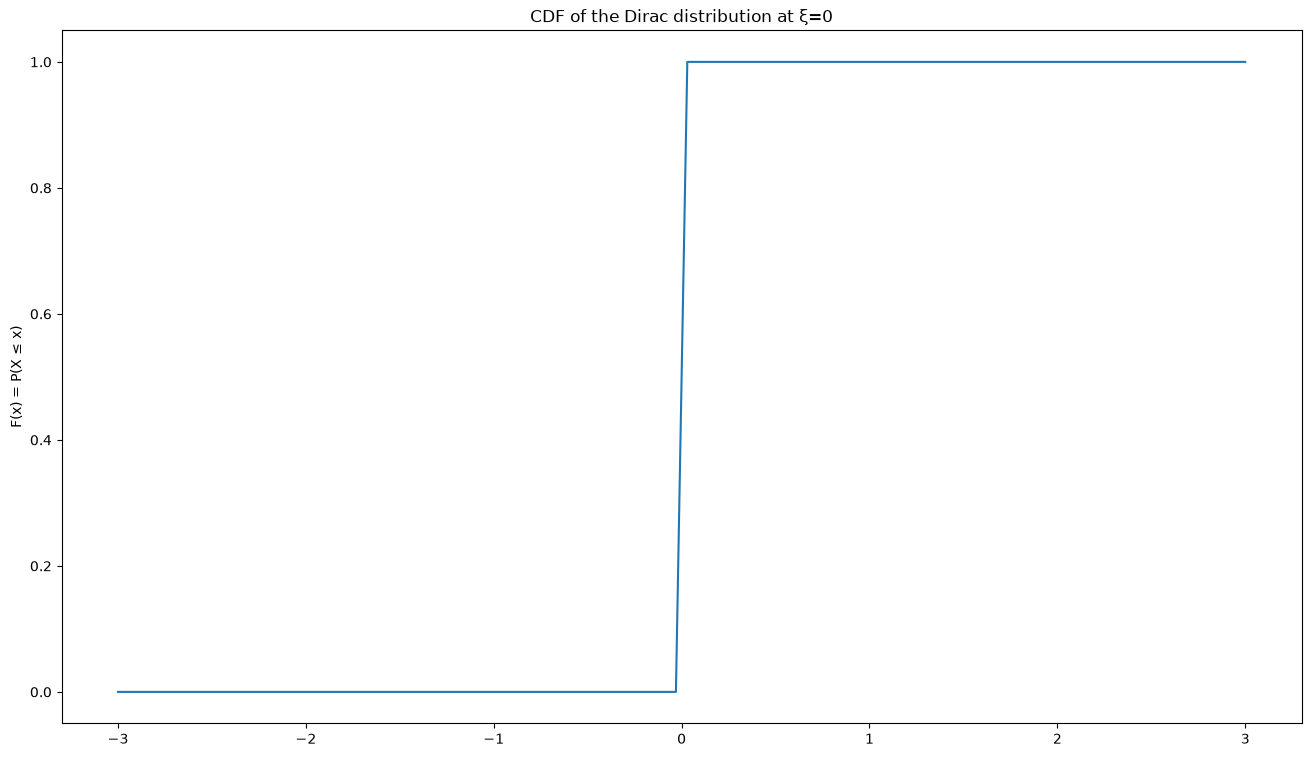

In [10]:
name = "Dirac distribution at ξ=0"
plt.plot(x, np.heaviside(x, 1))
plt.ylabel('F(x) = P(X ≤ x)')
plt.title("CDF of the "+name)
plt.show()

## Continuous uniform distribution

* Parameters $a,b$, notation $U([a,b])$
* Density $\frac{1}{b-a}$
* Expected value $\frac{a+b}{2}$
* Variance $\frac{(a-b)^2}{12}$
* Maximum entropy among all distributions with support $[a,b]$
* Example applications:
  * If a bus arrives at your stop extremely punctually every hour but you do not know when the last one left, your waiting time at the stop, in minutes, is uniformly distributed on $[0,60]$.
  * The temperature of your CPU from the third decimal place on, `(T * 100 - int(T * 100))`, is approximately uniformly distributed.

0.5 0.75


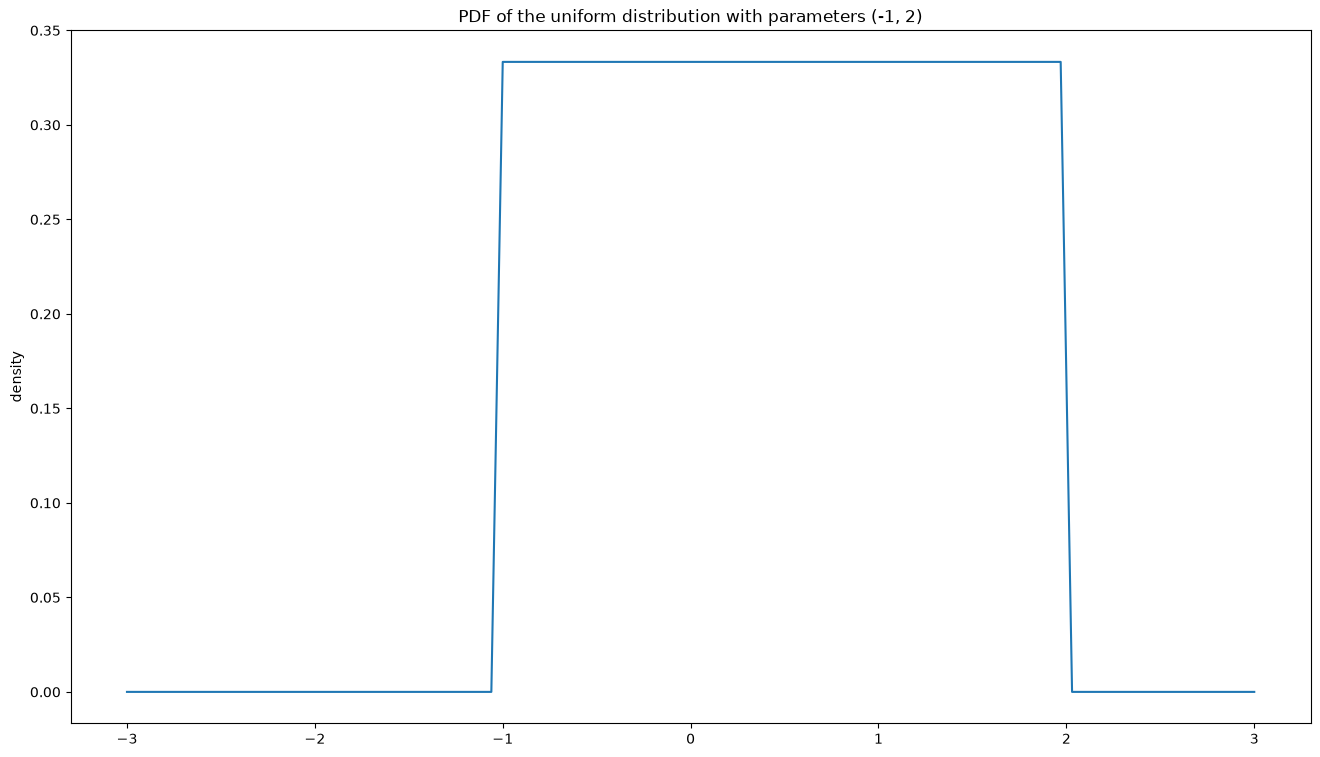

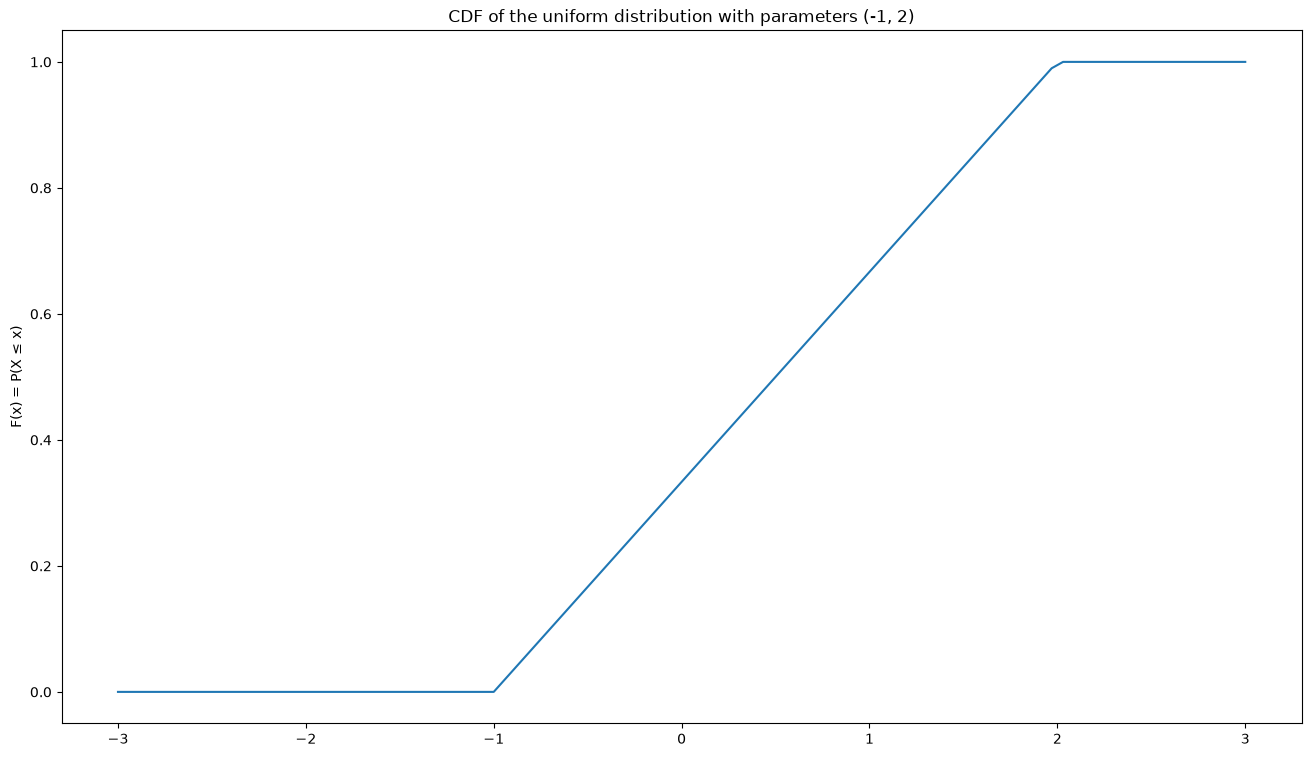

In [11]:
a, b = -1, 2
X = st.uniform(loc=a, scale=b-a)
print(X.mean(), X.var())
name = "uniform distribution"
plotX(x, X, name, (a, b))

## Exponential distribution

* Parameter $\lambda$, notation $Exp(\lambda)$
* Density $\lambda e^{-\lambda x}$ for $x \geq 0$ (and $0$ for $x < 0$)
* Expected value $\dfrac{1}{\lambda}$
* Variance $\dfrac{1}{\lambda^2}$
* Maximum entropy among all distributions with support $[0,\infty)$ and expected value $\dfrac{1}{\lambda}$
* Example applications:
  * How long does it take until the next packet arrives at the server?

The exponential distribution is the continuous flip side of the Poisson distribution from the chapter
[The most important discrete distributions](important-discrete-distributions.ipynb): count the
events per unit of time and there are $\operatorname{Pois}(\lambda)$ many of them; ask instead
for the waiting time until the next event, and it is
$\operatorname{Exp}(\lambda)$-distributed. In both cases $\lambda$ is the same rate.


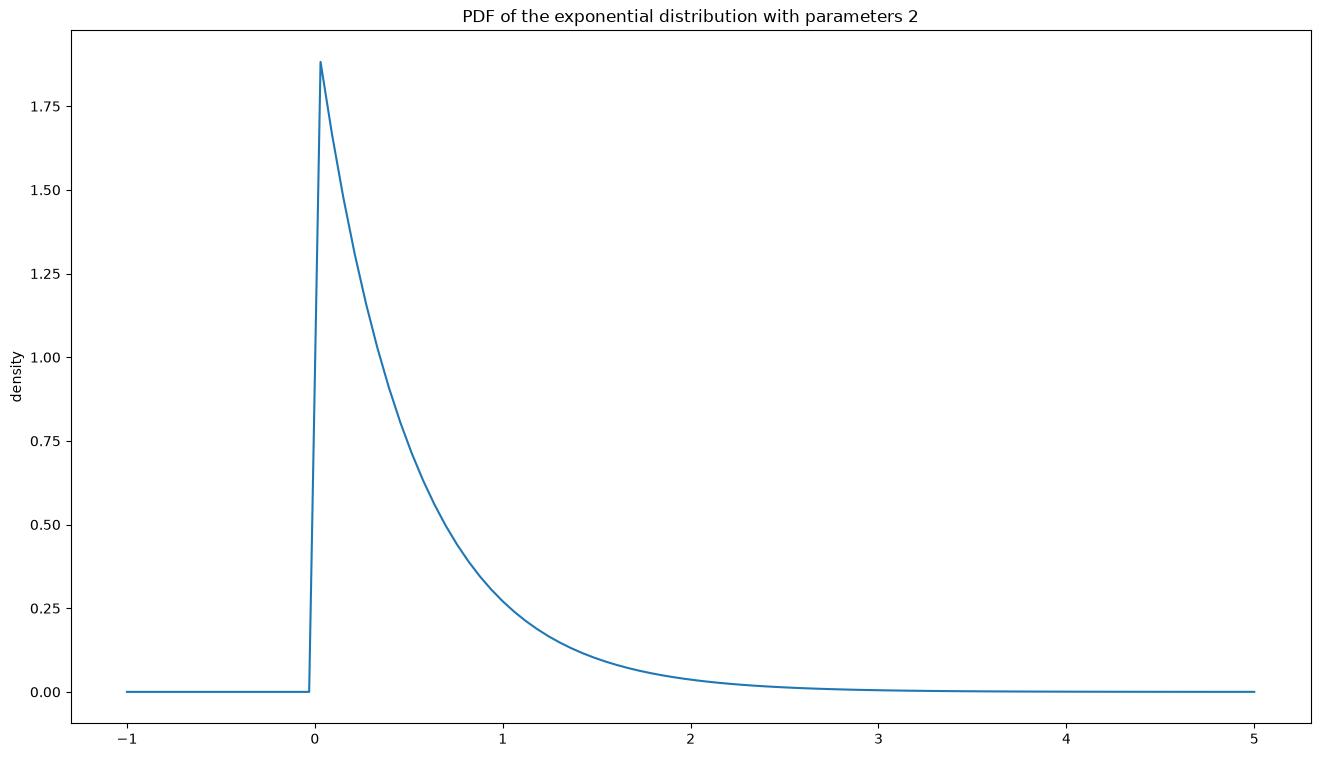

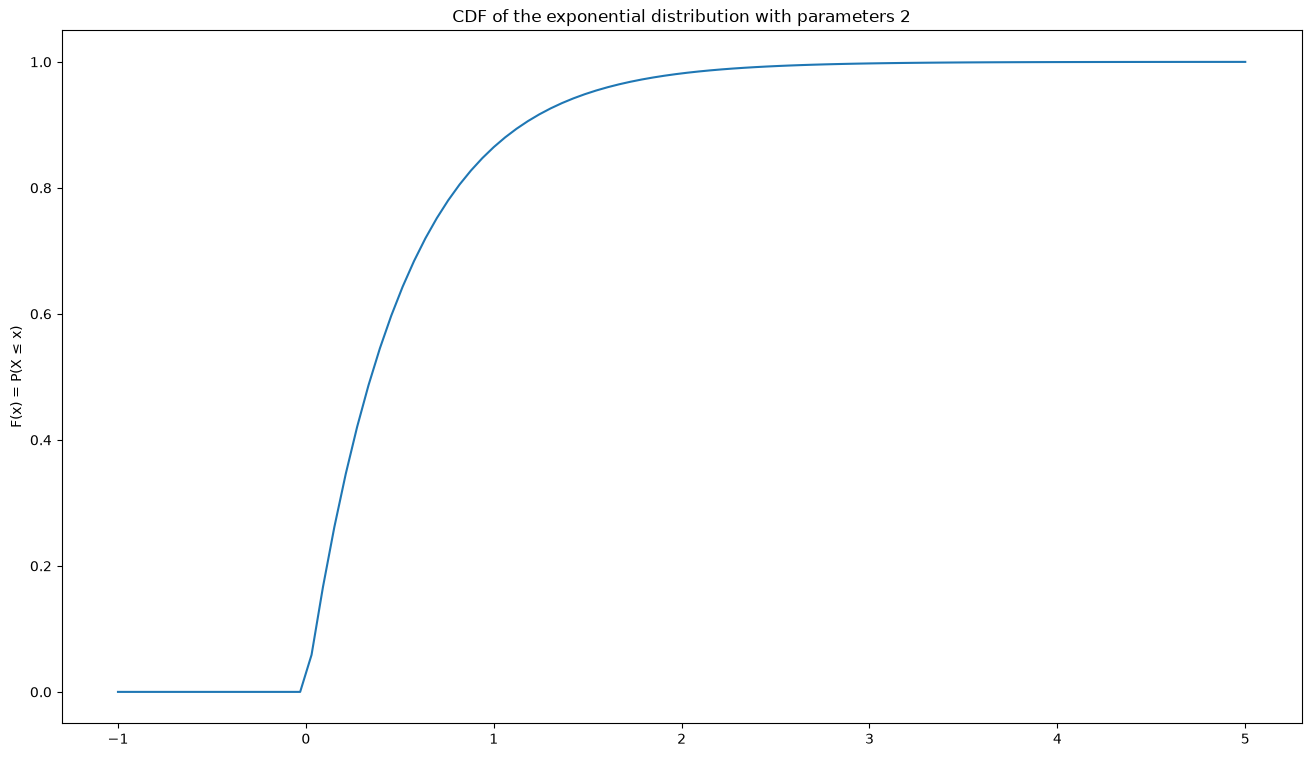

In [12]:
name = "exponential distribution"
lamda = 2   # 'lambda' is a keyword in Python (anonymous functions), hence the spelling
X = st.expon(scale = 1/lamda)
x = np.linspace(-1,5,100)
plotX(x,X,name,(lamda))

## Log-normal distribution

* Parameters $\mu, \sigma$, notation $Lognormal(\mu,\sigma^2)$
* Density $\frac{1}{x\sigma\sqrt{2\pi}} e^{-\frac{(\log(x)-\mu)^2}{2\sigma^2}}$
* Expected value $e^{\mu + \frac{\sigma^2}{2}}$, but $\mathbb{E}(\log X) = \mu$
* Variance $(e^{\sigma^2}-1)e^{2\mu + \sigma^2}$, but $\mathbb{V}(\log X) = \sigma^2$
* Maximum entropy among all distributions with support $(0,\infty)$ and $\mathbb{E}(\log X) = \mu$ and $\mathbb{V}(\log X) = \sigma^2$
* Example applications:
  * The length of a game of chess is log-normally distributed
  * Many (!) more examples are listed in [Wikipedia on the log-normal distribution](https://en.wikipedia.org/wiki/Log-normal_distribution#Occurrence_and_applications)

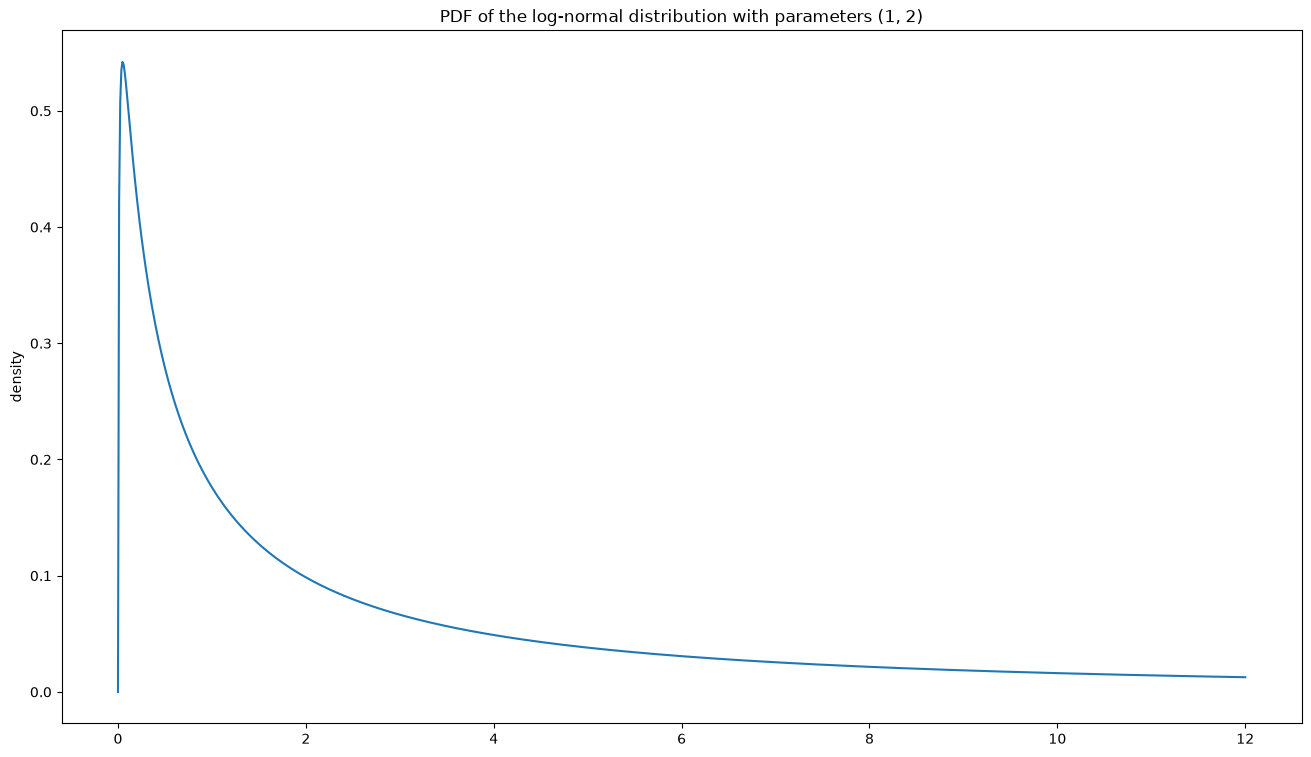

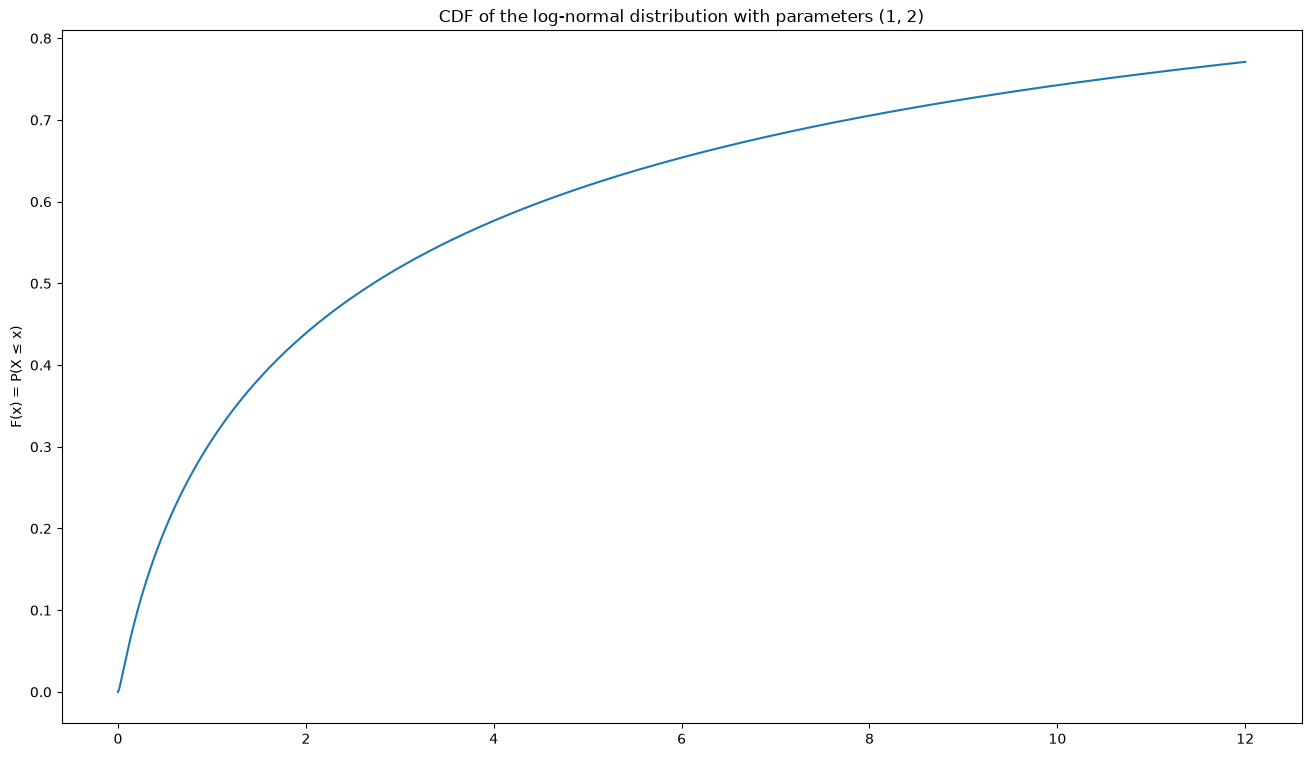

In [13]:
name = "log-normal distribution"
mu, sigma = 1, 2
X = st.lognorm(s=sigma, scale = np.exp(mu))
x = np.linspace(0, 12, 1000)
plotX(x,X,name,(mu, sigma))

## Weibull distribution

* Parameters $\lambda>0, k>0$, notation $Weibull(\lambda,k)$
* Density $f(x) = \dfrac{k}{\lambda}   {\left(\frac{x}{\lambda}\right)}^{k-1}    e^{-{\left(\frac{x}{\lambda}\right)}^k}$ for $x \geq 0$ \
  and $f(x)=0$ for $x < 0$
* Expected value $\lambda \Gamma(1+\frac{1}{k})$ (where $\Gamma(n+1) = n!$)
* Variance $\lambda^2 \left[ \Gamma(1+\frac{2}{k}) - \Gamma(1+\frac{1}{k})^2 \right]$
* Maximum entropy among all distributions with support $[0,\infty)$, fixed $\mathbb{E}(X^k)$ and fixed $\mathbb{E}(\log X)$ – so the shape parameter $k$ says which moment is held fixed
* Example applications:
  * How long does a heat pump run before it breaks down?
  * What is the wind speed?
  * What is the largest amount of precipitation to fall on a single day in the year?

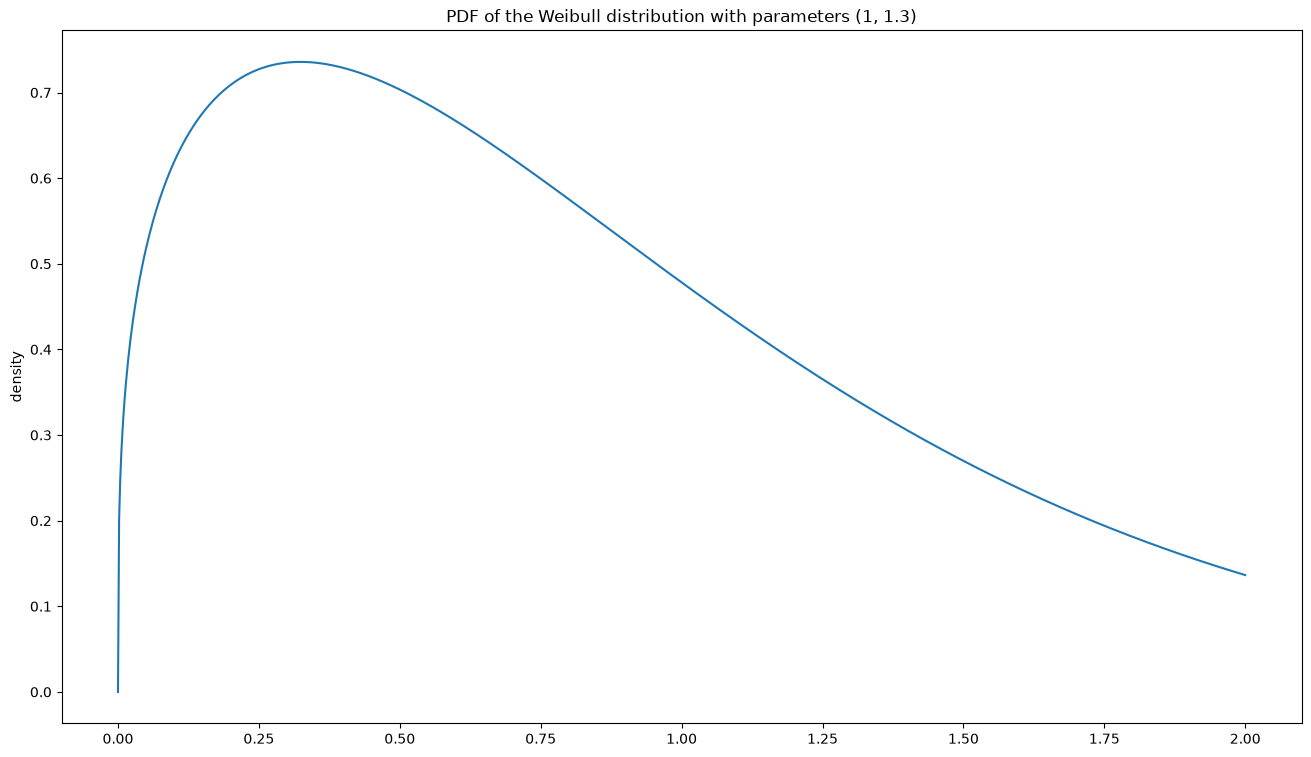

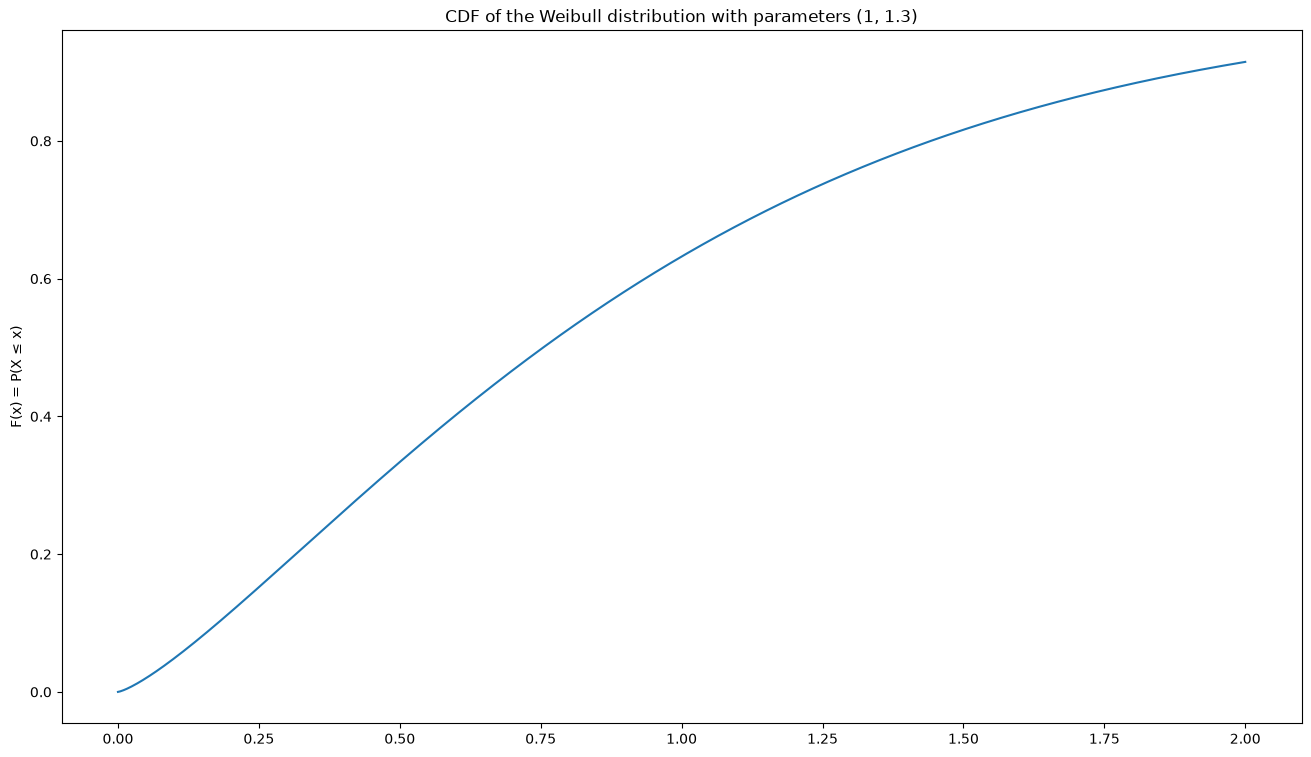

In [14]:
name = "Weibull distribution"
lamda, k = 1, 1.3   # lamda: see above
X = st.weibull_min(c=k, loc=0, scale = lamda)
x = np.linspace(0,2,1000)
plotX(x,X,name,(lamda, k))

## Data to plot and fit

To get a little practice in plotting data and fitting distributions to it (and then visualising the fit in a plot), we need some toy data.

A very simple, and therefore very instructive, dataset is Fisher and Anderson's 'iris flower dataset', which we can get from Scikit-Learn, for instance:

In [15]:
from sklearn import datasets
iris = datasets.load_iris()
print(iris["data"][:5])

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]


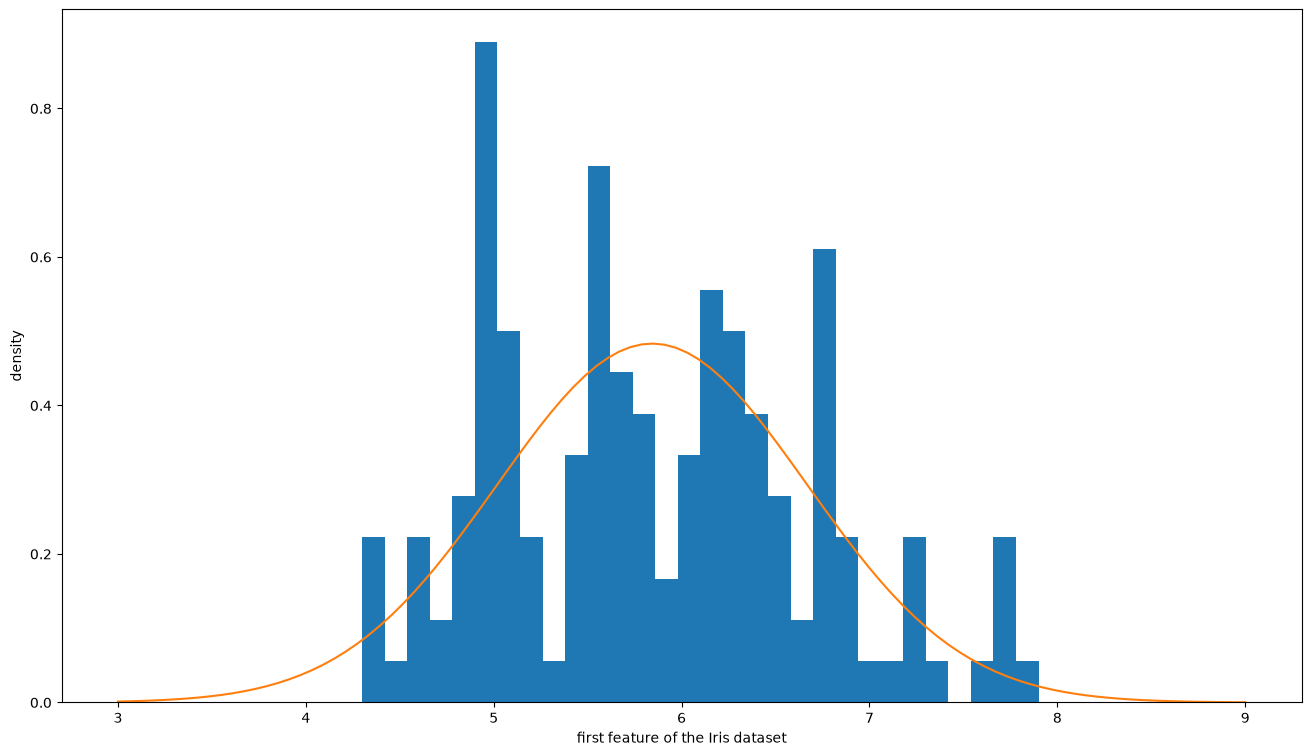

In [16]:
first_feature = iris["data"][:,0]
plt.hist(first_feature, bins=30, density=True)
# Now the best-fitting normal distribution on top:
mu, sigma = st.norm.fit(first_feature)
X = st.norm(loc=mu, scale=sigma)
x = np.linspace(3,9,100)
plt.plot(x, X.pdf(x))
plt.xlabel("first feature of the Iris dataset")
plt.ylabel("density")
plt.show()

One source of reasonably well-maintained and much-discussed toy data is [Kaggle](https://www.kaggle.com/datasets).
To work with these data you usually have to turn CSV files into Numpy arrays. That is particularly painless with Pandas (which builds on Numpy), which we will come to; for now, Numpy's built-in `np.genfromtxt` will do.

In its [Climate Data Center](https://cdc.dwd.de/portal/) (in German), the German weather service DWD keeps a large collection of well-documented weather and climate data, some of it updated daily. It holds spatially distributed variables and time series of all manner of physical quantities and statistical distributions. One interesting (and answerable) question, for instance, is whether heavy rainfall events in Düsseldorf have become more frequent over the last few decades.

Have a look at these (and other!) data, work out how the variables might be distributed, plot the distributions and fit them. Comparing the histogram with the density function of the fitted distribution is the best way to see how close we are.

Since a great deal of data fits none of the distributions listed here, we need more complex models as well. Mostly, though, these are assembled in stages from the simple models, as with the contaminated normal distribution. One of the most important will later be the mixture of multivariate normal distributions, which lets us look at some of the principles of machine learning.

If you want to dig further into the relationships between the distributions – and have noticed that several of them can perfectly well be parametrised in different ways (the normal distribution with $\mu,\sigma$, say, but also with $\mu,\sigma^2$) – then ProbOnto may be just the thing. It is an ontology and knowledge base originally developed for pharmacology. The overview diagram alone is already a good memory aid:

```{figure} images/ProbOnto2.5.jpg
---
width: 100%
name: probonto-diagram
---
[ProbOnto 2.5](https://commons.wikimedia.org/wiki/File:ProbOnto2.5.jpg) CC-BY-SA [Wikipedia user Fuzzyrandom](https://commons.wikimedia.org/w/index.php?title=User:Fuzzyrandom)